Los mapas de calor son ideales para:

Ver correlaciones entre variables numéricas (−1 a +1).
Detectar patrones en tablas (p. ej. valores por mes/año).
Comunicar de forma compacta grandes cantidades de números.
Todos los ejemplos incluyen imports y set_theme para copiar/pegar y ejecutar con Seaborn ≥ 0.12/0.13.

5.1 Matrices de correlación con heatmap
A) Correlación básica (con anotaciones)

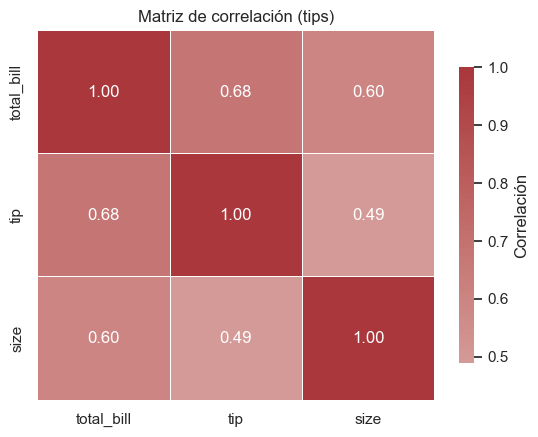

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

# Dataset de ejemplo
tips = sns.load_dataset("tips")

# Matriz de correlación solo con columnas numéricas
corr = tips.corr(numeric_only=True)

# Mapa de calor con anotaciones y paleta divergente centrada en 0
ax = sns.heatmap(
    corr,
    annot=True, fmt=".2f",
    cmap="vlag", center=0,
    linewidths=0.5, linecolor="white",
    cbar_kws={"shrink": .8, "label": "Correlación"}
)
ax.set_title("Matriz de correlación (tips)")
plt.show()

B) Correlación mostrando solo media matriz (enmascarar triángulo superior)

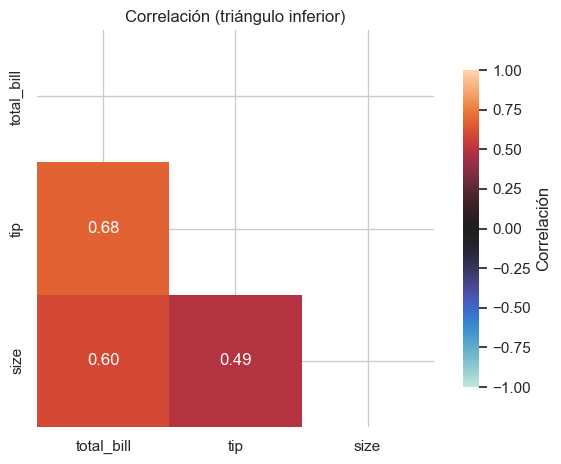

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")
corr = tips.corr(numeric_only=True)

# Máscara para ocultar el triángulo superior
mask = np.triu(np.ones_like(corr, dtype=bool))

ax = sns.heatmap(
    corr,
    mask=mask,
    annot=True, fmt=".2f",
    cmap="icefire", center=0,
    vmin=-1, vmax=1,        # escala consistente
    square=True,
    cbar_kws={"shrink": .8, "label": "Correlación"}
)
ax.set_title("Correlación (triángulo inferior)")
plt.tight_layout()
plt.show()

C) Correlación en otro dataset (Iris) y orden por clúster

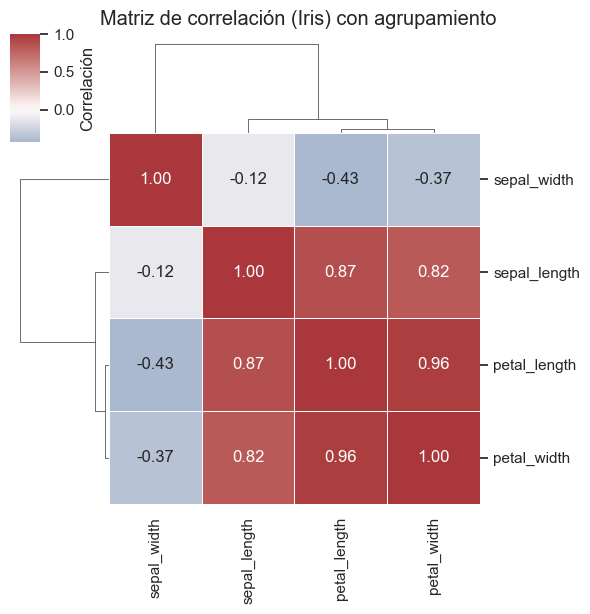

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
iris = sns.load_dataset("iris")

corr = iris.drop(columns=["species"]).corr()

# clustermap reordena filas/columnas por similitud (jerárquico)
g = sns.clustermap(
    corr,
    annot=True, fmt=".2f",
    cmap="vlag", center=0,
    linewidths=.5, figsize=(6, 6),
    cbar_kws={"label": "Correlación"}
)
g.fig.suptitle("Matriz de correlación (Iris) con agrupamiento", y=1.02)
plt.show()

Buenas prácticas de correlación
Usá paletas divergentes centradas en 0 (cmap="vlag" o "coolwarm") para resaltar negativos vs positivos.
Mantener vmin=-1 y vmax=1 evita “estirar” colores según cada dataset.
Si hay muchas variables, clustermap ayuda a ver bloques de alta relación.

5.2 Mapas de calor personalizados
A) Pivot + heatmap (por ejemplo, tabla Mes × Año)

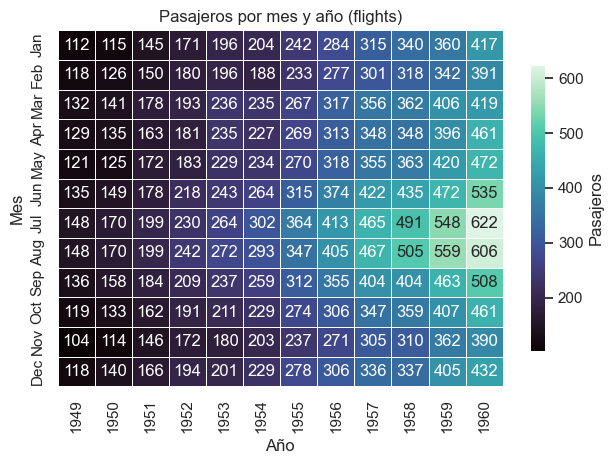

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")

# Dataset flights: pasajeros por mes/año
flights = sns.load_dataset("flights")  # columns: year, month, passengers

# Crear tabla: filas=mes, columnas=año, valores=pasajeros
tabla = flights.pivot(index="month", columns="year", values="passengers")

ax = sns.heatmap(
    tabla,
    cmap="mako",          # secuencial: ideal para magnitudes
    annot=True, fmt="d",  # números enteros
    linewidths=.4, linecolor="white",
    cbar_kws={"shrink": .8, "label": "Pasajeros"}
)
ax.set_title("Pasajeros por mes y año (flights)")
ax.set_xlabel("Año")
ax.set_ylabel("Mes")
plt.tight_layout()
plt.show()

B) Escala de color, anotaciones y formato

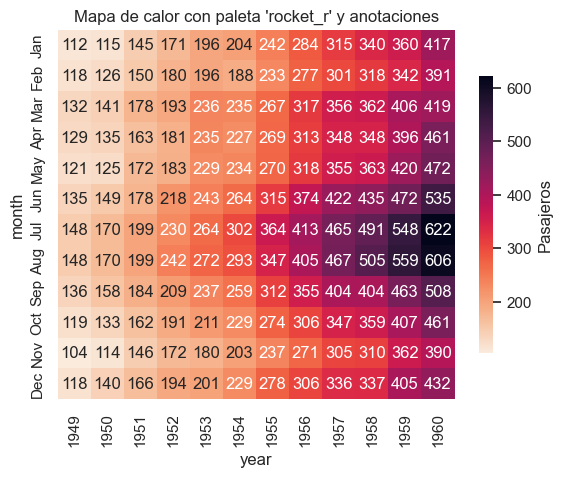

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")
flights = sns.load_dataset("flights")
tabla = flights.pivot(index="month", columns="year", values="passengers")

# Personalización avanzada
ax = sns.heatmap(
    tabla,
    cmap="rocket_r",      # versión invertida de 'rocket'
    annot=True, fmt=".0f",
    vmax=tabla.values.max(), vmin=tabla.values.min(),  # fija escala completa
    cbar_kws={"orientation": "vertical", "shrink": .75, "label": "Pasajeros"},
    square=False
)
ax.set_title("Mapa de calor con paleta 'rocket_r' y anotaciones")
plt.show()

C) Normalizar por filas/columnas antes de graficar (comparaciones justas)
A veces querés comparar patrones relativos en cada fila/columna (no los valores brutos).

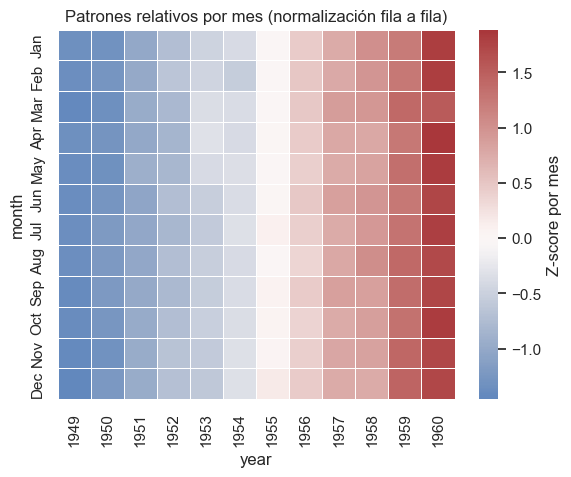

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")
flights = sns.load_dataset("flights")
tabla = flights.pivot(index="month", columns="year", values="passengers")

# Normalizar POR FILA: (valor - media_fila) / desvío_fila
tabla_norm = tabla.apply(lambda s: (s - s.mean()) / s.std(ddof=0), axis=1)

ax = sns.heatmap(
    tabla_norm,
    cmap="vlag", center=0,   # centrado en 0 para ver arriba/abajo de la media
    linewidths=.4,
    cbar_kws={"label": "Z-score por mes"}
)
ax.set_title("Patrones relativos por mes (normalización fila a fila)")
plt.show()

D) Enmascarar valores (p. ej., por debajo de un umbral)

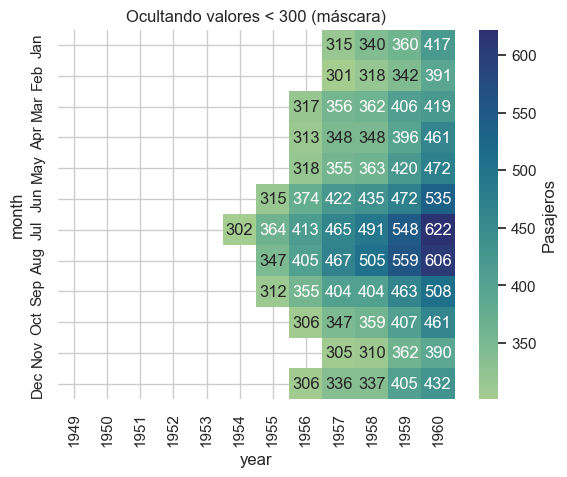

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid", context="notebook")
flights = sns.load_dataset("flights")
tabla = flights.pivot(index="month", columns="year", values="passengers")

# Máscara: ocultar celdas con menos de 300 pasajeros
mask = tabla < 300

ax = sns.heatmap(
    tabla,
    mask=mask,
    cmap="crest",
    annot=True, fmt="d",
    cbar_kws={"label": "Pasajeros"}
)
ax.set_title("Ocultando valores < 300 (máscara)")
plt.show()

E) Ajustes de estilo frecuentes

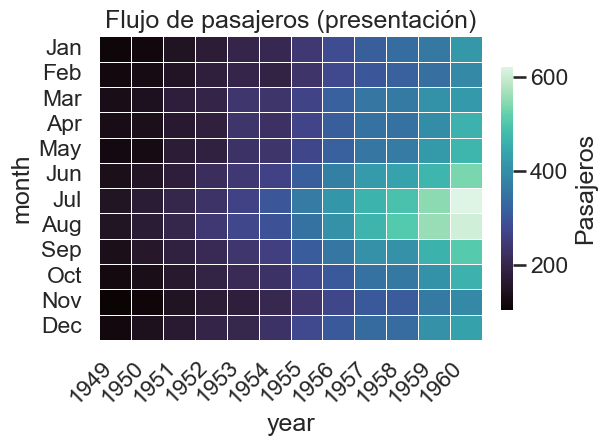

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="whitegrid", context="talk")  # context='talk' para presentaciones

flights = sns.load_dataset("flights")
tabla = flights.pivot(index="month", columns="year", values="passengers")

ax = sns.heatmap(
    tabla,
    cmap="mako",
    annot=False,
    linewidths=.5,
    cbar_kws={"shrink": .8, "pad": .04, "label": "Pasajeros"}
)

# Rotación de etiquetas y ajuste de layout
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
ax.set_title("Flujo de pasajeros (presentación)")
plt.tight_layout()
plt.show()

5.3 Consejos rápidos y buenas prácticas
Correlación ⇒ paleta divergente centrada en 0 ("vlag", "coolwarm", "icefire").
Magnitudes ⇒ paleta secuencial ("mako", "rocket", "viridis", "crest").
Anotaciones (annot=True): útiles para leer valores exactos; evitarlas si hay demasiadas celdas.
Escala coherente: fija vmin/vmax cuando compares varios heatmaps.
Normalizar por fila/columna cuando importa el patrón relativo más que el valor bruto.
Máscaras: ayudan a centrar la lectura en zonas de interés.
Clúster (clustermap): revela grupos de variables similares automáticamente.
Accesibilidad: elegí paletas legibles y suficiente contraste; rotá etiquetas para evitar solapamiento.

Mini-checklist
¿Es correlación? → corr(numeric_only=True) + heatmap(..., cmap="vlag", center=0, vmin=-1, vmax=1).
¿Tabla Mes×Año u otra pivoteada? → pivot() + heatmap con paleta secuencial.
¿Comparación relativa? → normalizá por filas/columnas y centrado en 0.
¿Demasiada información? → mascará o usá clustermap para reordenar.